In [29]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/hassanraof/telcocustomerchurn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [30]:
df = pd.read_csv("/kaggle/input/datasets/hassanraof/telcocustomerchurn/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [31]:
df.shape


(7043, 21)

In [32]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [33]:
df = df.drop(columns=["customerID"])

In [34]:
df = pd.read_csv("/kaggle/input/datasets/hassanraof/telcocustomerchurn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [35]:
df = df.drop(columns=["customerID"])

In [36]:
df = pd.read_csv("/kaggle/input/datasets/hassanraof/telcocustomerchurn/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = df.drop(columns=["customerID"], errors="ignore")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df[df["TotalCharges"].isnull()][["tenure", "TotalCharges"]].head())
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(df.isnull().sum().sum())
print(df["Churn"].value_counts())

      tenure  TotalCharges
488        0           NaN
753        0           NaN
936        0           NaN
1082       0           NaN
1340       0           NaN
0
Churn
0    5174
1    1869
Name: count, dtype: int64


In [37]:
print(df.groupby("Contract")["Churn"].mean())

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64


In [38]:
print(df.groupby("InternetService")["Churn"].mean())
print(df.groupby("PaymentMethod")["Churn"].mean())

InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn, dtype: float64
PaymentMethod
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Electronic check             0.452854
Mailed check                 0.191067
Name: Churn, dtype: float64


In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

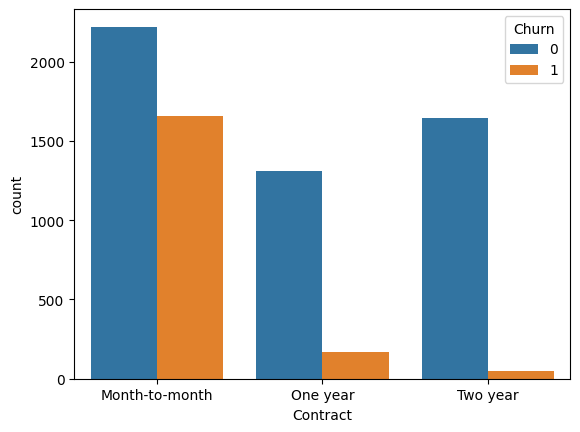

In [40]:
sns.countplot(x="Contract", hue="Churn", data=df)
plt.show()

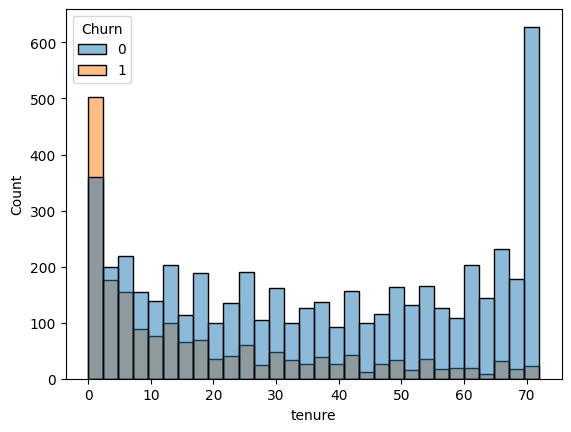

In [41]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30)
plt.show()

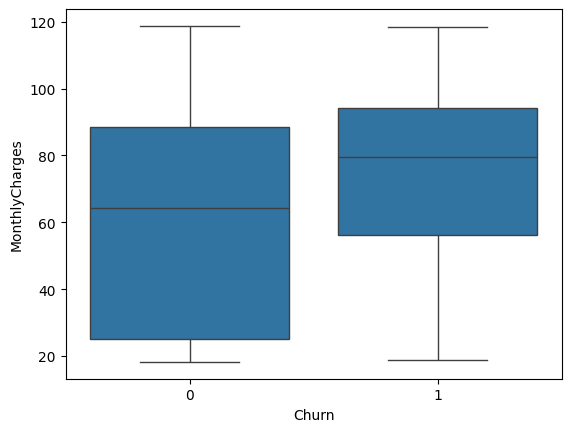

In [42]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.show()

In [43]:
print(df.select_dtypes("number").corr()["Churn"].sort_values())

tenure           -0.352229
TotalCharges     -0.198324
SeniorCitizen     0.150889
MonthlyCharges    0.193356
Churn             1.000000
Name: Churn, dtype: float64


In [44]:
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True).astype(float)
y = df["Churn"]
print(X.shape)

(7043, 30)


In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(5634, 30) (1409, 30)
0.2653532126375577 0.2654364797728886


In [46]:
baseline = 1 - y_test.mean()
print("Accuracy of always predicting 'stays':", round(baseline, 3))

Accuracy of always predicting 'stays': 0.735


In [47]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1,
                             max_depth=4, random_state=42,
                             eval_metric="logloss"),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(name, "| test accuracy:", round(m.score(X_test, y_test), 3))

Logistic Regression | test accuracy: 0.807
Random Forest | test accuracy: 0.793
XGBoost | test accuracy: 0.798


In [48]:
from sklearn.metrics import (precision_score, recall_score,
                             f1_score, roc_auc_score, accuracy_score)

rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).round(3)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.807,0.658,0.567,0.609,0.842
1,Random Forest,0.793,0.637,0.511,0.567,0.826
2,XGBoost,0.798,0.648,0.521,0.578,0.839


In [49]:
from sklearn.model_selection import cross_val_predict

lr = models["Logistic Regression"]
proba_cv = cross_val_predict(lr, X_train, y_train, cv=5,
                             method="predict_proba")[:, 1]

for t in [0.5, 0.4, 0.35, 0.3, 0.25]:
    pred = (proba_cv >= t).astype(int)
    print(t, "| recall:", round(recall_score(y_train, pred), 3),
          "| precision:", round(precision_score(y_train, pred), 3),
          "| F1:", round(f1_score(y_train, pred), 3))

0.5 | recall: 0.55 | precision: 0.657 | F1: 0.599
0.4 | recall: 0.662 | precision: 0.597 | F1: 0.627
0.35 | recall: 0.706 | precision: 0.567 | F1: 0.629
0.3 | recall: 0.765 | precision: 0.538 | F1: 0.632
0.25 | recall: 0.815 | precision: 0.51 | F1: 0.627


In [50]:
best_t = 0.35   # change this after looking at Cell 1

proba_test = lr.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= best_t).astype(int)

print("Threshold:", best_t)
print("Recall:", round(recall_score(y_test, pred_test), 3))
print("Precision:", round(precision_score(y_test, pred_test), 3))
print("F1:", round(f1_score(y_test, pred_test), 3))
print(confusion_matrix(y_test, pred_test))

Threshold: 0.35
Recall: 0.709
Precision: 0.544
F1: 0.616
[[813 222]
 [109 265]]


In [51]:
import joblib, sklearn

artifact = {"model": lr, "columns": list(X.columns), "threshold": 0.35}
joblib.dump(artifact, "churn_model.pkl")
print("sklearn version:", sklearn.__version__)

sklearn version: 1.6.1


In [52]:
from sklearn.metrics import confusion_matrix

for name, m in models.items():
    print(name)
    print(confusion_matrix(y_test, m.predict(X_test)))
    print()

Logistic Regression
[[925 110]
 [162 212]]

Random Forest
[[926 109]
 [183 191]]

XGBoost
[[929 106]
 [179 195]]

